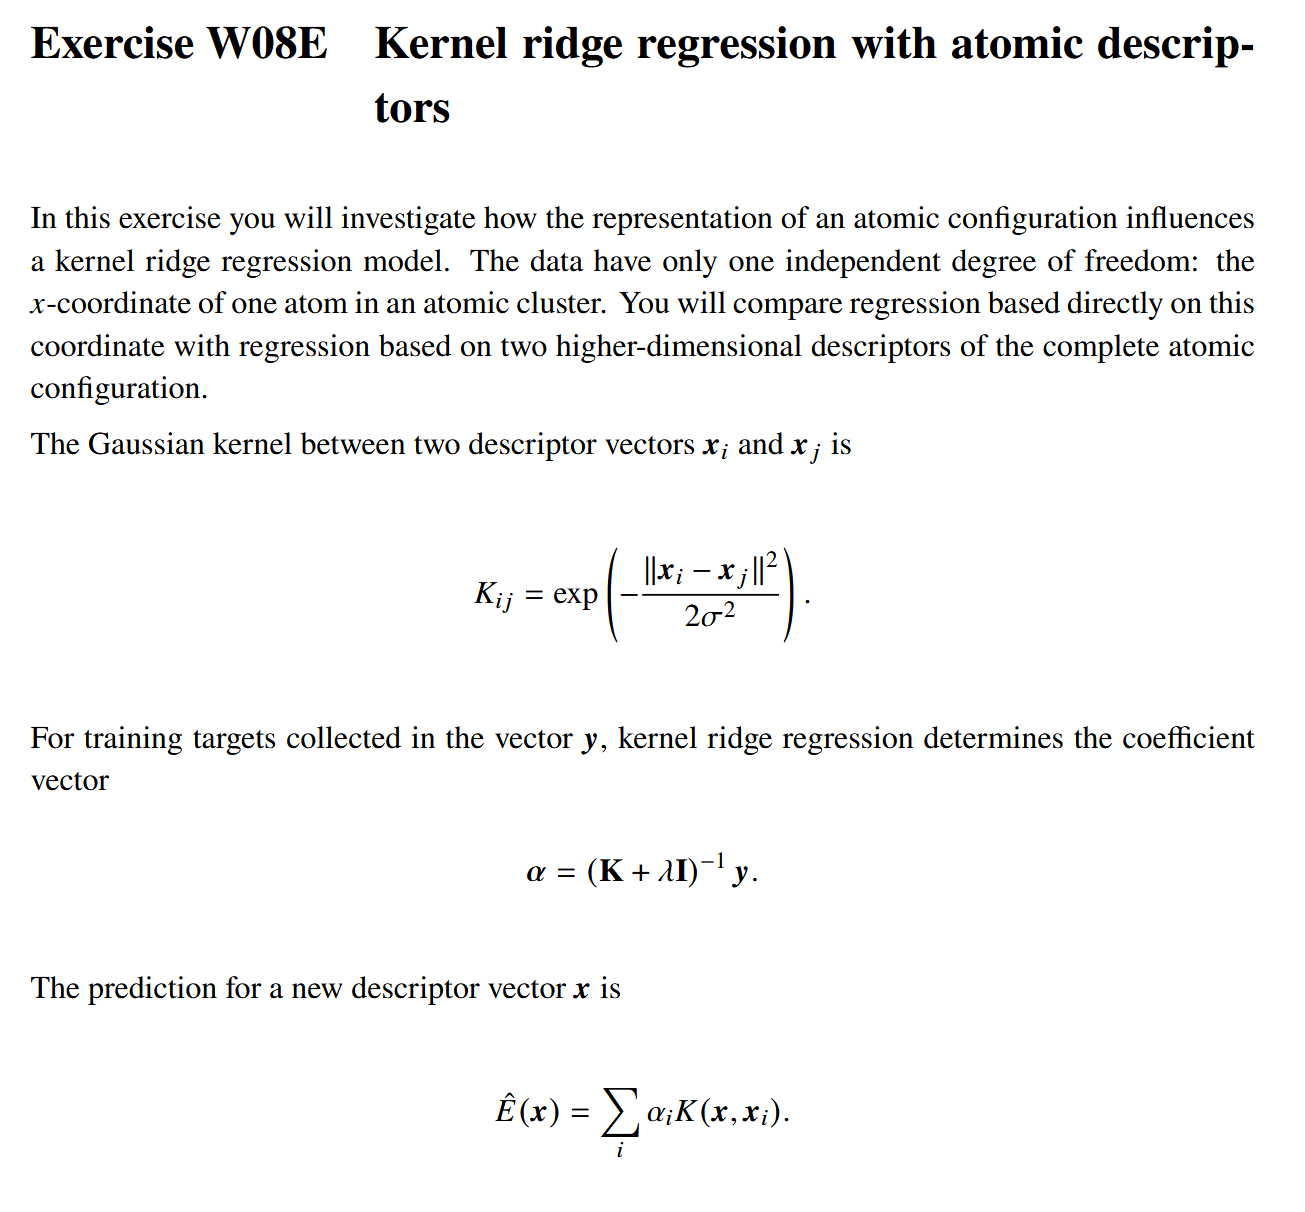
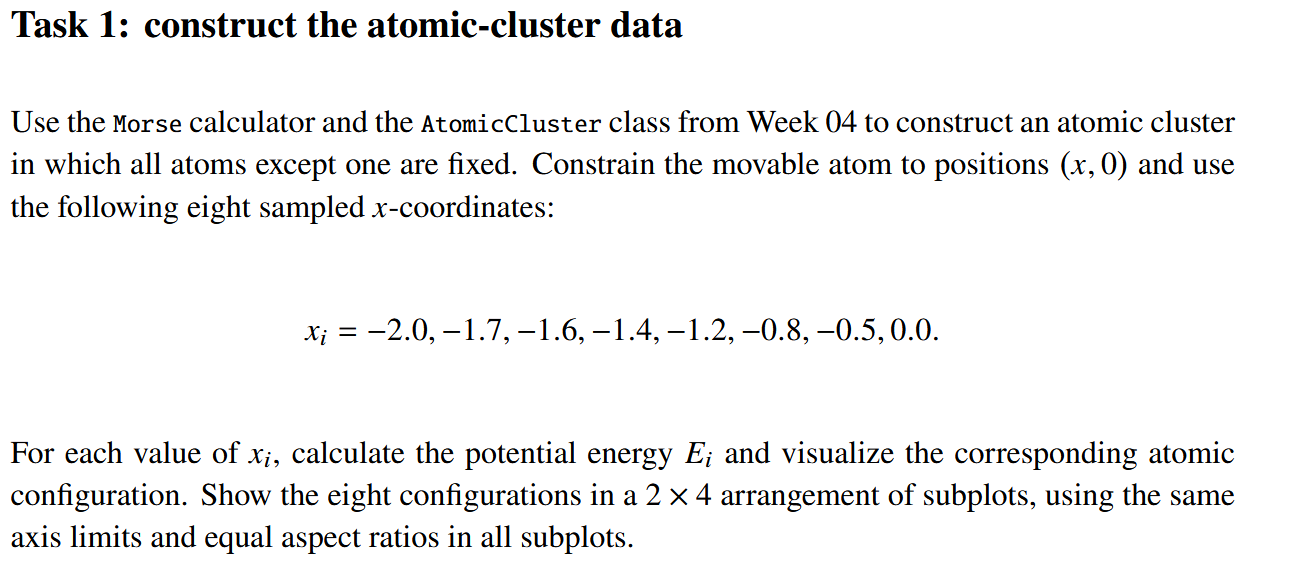
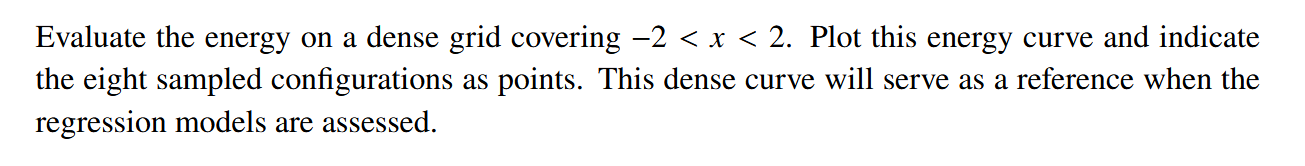

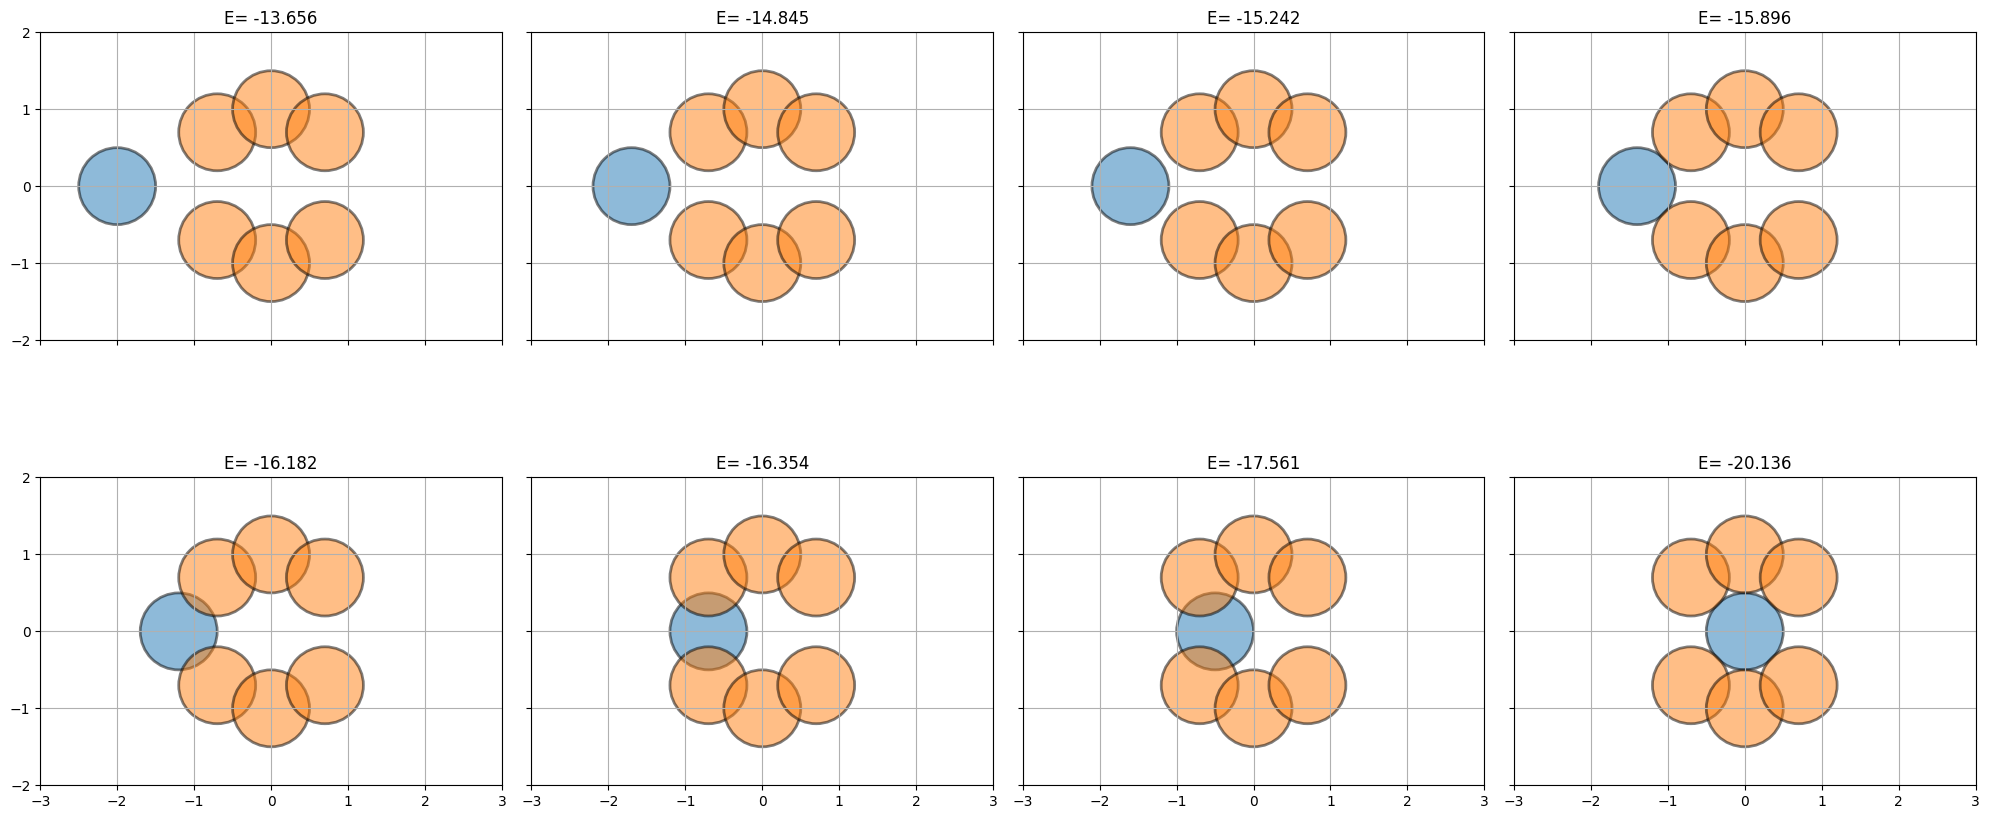

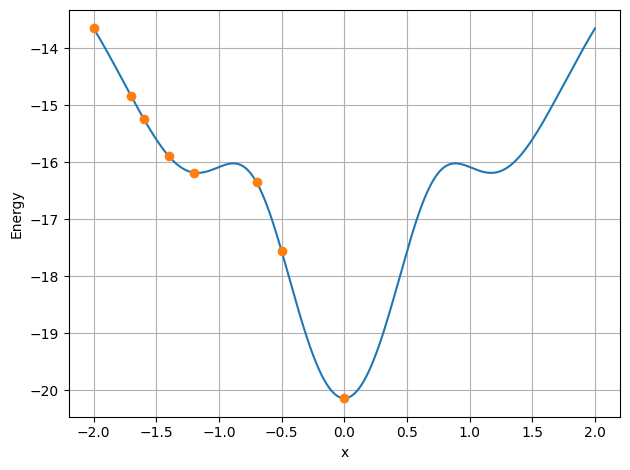

In [11]:
import numpy as np
import matplotlib.pyplot as plt 
from Regression import *
from week04 import *

calc = Morse()

pos = [(0.0, 0.0), (-0.7, 0.7), (0, 1), (0.7, 0.7), (-0.7, -0.7), (0, -1), (0.7, -0.7)]
N = len(pos)
static = [False] + [True] * (N-1)

cluster = AtomicCluster(calc, pos=pos, static=static)

xi = [-2.0, -1.7, -1.6, -1.4, -1.2, -0.7, -0.5, 0.0]

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten()

E_points = []

def potential(xlist):
    if type(xlist) != np.ndarray and type(xlist) != list:
        cluster.pos[0] = (xlist, 0.0)
        return cluster.potential_energy
    else: 
        energy = []
        for x in xlist:
            cluster.pos[0] = (x, 0.0)
            e = cluster.potential_energy
            energy.append(e)
        return energy

for x, ax in zip(xi, axes): 
    E = potential(x)
    E_points.append(E)
    cluster.draw(ax)
    nice_plot(ax)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-2, 2)

fig.tight_layout()

fig, ax = plt.subplots(1, 1)

xlin = np.linspace(-2, 2, 1000)
ax.plot(xlin, potential(xlin))
ax.plot(xi, potential(xi), 'o')
ax.grid()
ax.set_xlabel('x')
ax.set_ylabel('Energy')
fig.tight_layout()

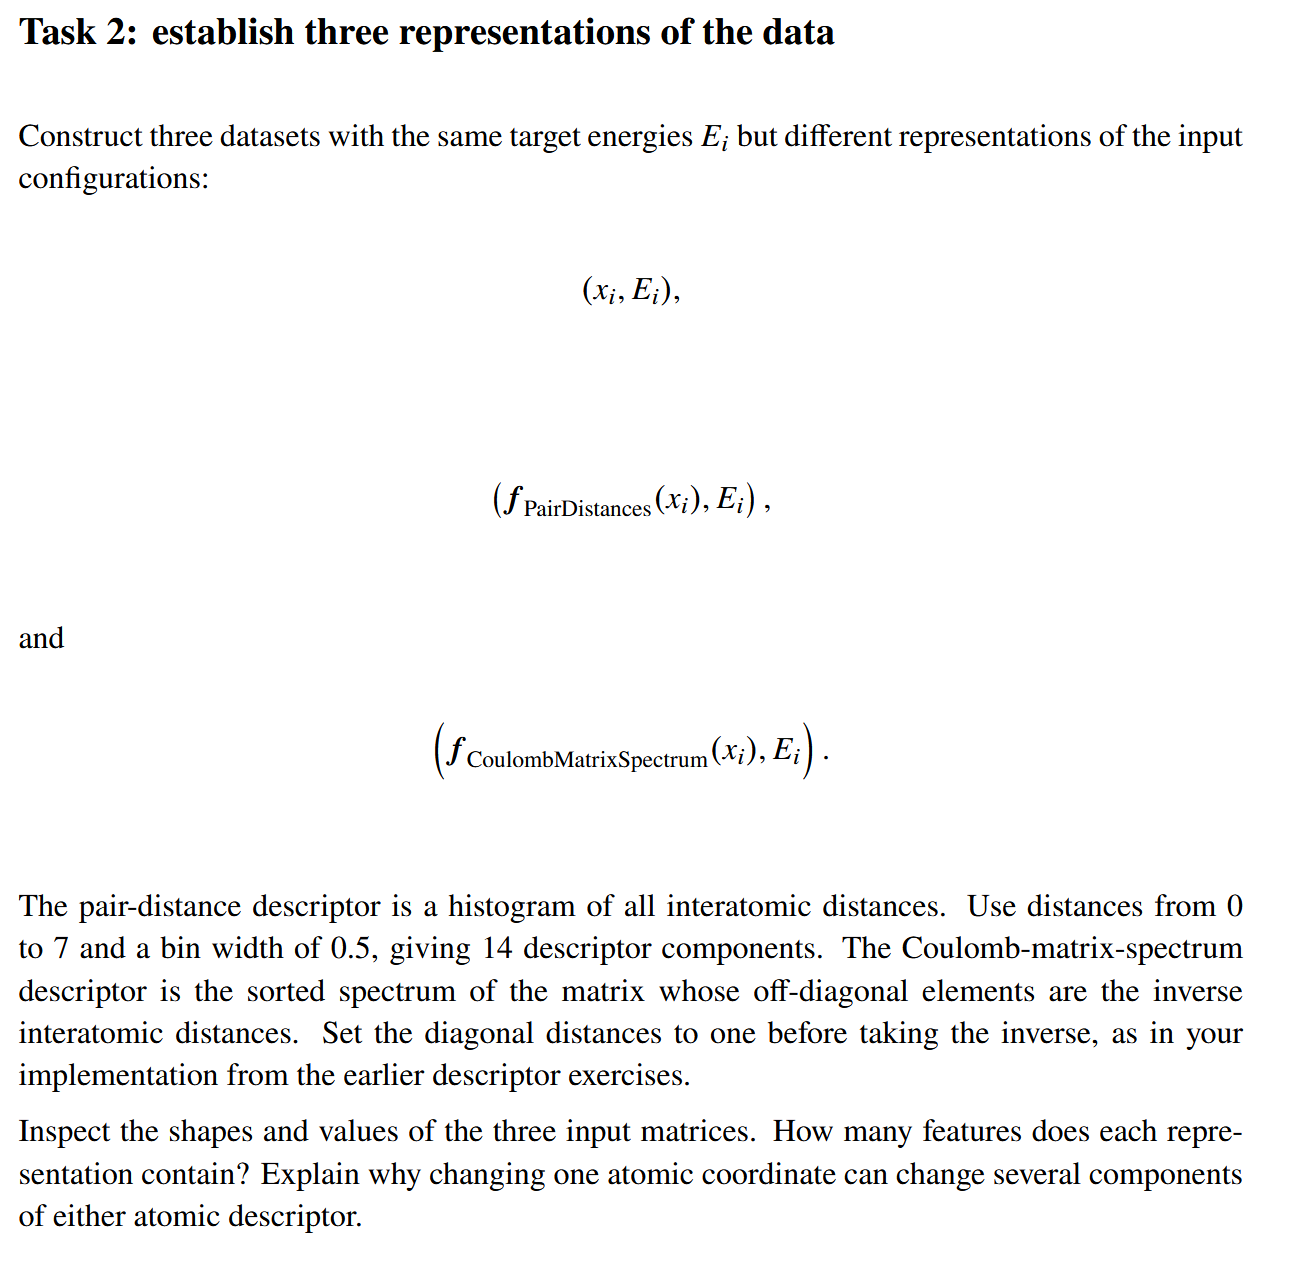

In [12]:
from scipy.spatial.distance import pdist, squareform

def PairDistance(x):
    cluster.pos[0] = (x, 0.0)
    dist = pdist(cluster.pos)
    hist, _ = np.histogram(dist, bins=np.arange(0, 7.5, 0.5))
    return hist 

def CoulombMatrixSpectrum(x):
    cluster.pos[0] = (x, 0.0)
    dist_matrix = squareform(pdist(cluster.pos))

    # Set diagonal distances to one before taking the inverse
    np.fill_diagonal(dist_matrix, 1.0)

    coulomb = 1.0 / dist_matrix

    eigval = np.linalg.eigvals(coulomb)

    return np.sort(eigval)[::-1]

Ei = np.array(E_points).reshape(-1, 1)

X1 = np.array(xi).reshape(-1, 1)
X2 = np.array([PairDistance(x) for x in xi])
X3 = np.array([CoulombMatrixSpectrum(x) for x in xi])

print(f"X1 (Coordinate) shape: {X1.shape}")
print(f"X2 (Pair Distances) shape: {X2.shape}")
print(f"X3 (Coulomb Spectrum) shape: {X3.shape}")
print(f"Ei (Energies) shape: {Ei.shape}")

X1 (Coordinate) shape: (8, 1)
X2 (Pair Distances) shape: (8, 14)
X3 (Coulomb Spectrum) shape: (8, 7)
Ei (Energies) shape: (8, 1)


### **Discussion Questions**

**How many features does each representation contain?**
* The coordinate representation ($X_1$) contains exactly 1 feature (the $x$-coordinate itself).


* The pair-distance descriptor ($X_2$) contains 14 features, corresponding to the 14 bins of the histogram ranging from 0 to 7 with a width of 0.5.


* The Coulomb-matrix-spectrum descriptor ($X_3$) contains 7 features, representing the sorted eigenvalues of the $7 \times 7$ matrix generated by the 7 atoms in the cluster.




**Explain why changing one atomic coordinate can change several components of either atomic descriptor.**
* Because the descriptors evaluate the relationships between all atoms, shifting just the single moving atom simultaneously changes its Euclidean distance to the other 6 static atoms in the cluster.


* In the pair-distance histogram, these 6 new distance values will cascade into different bins, altering multiple histogram components simultaneously.


* In the Coulomb matrix, changing one atom alters an entire row and column of the off-diagonal inverse distances, which consequently shifts the entire eigen-spectrum (modifying all 7 components).

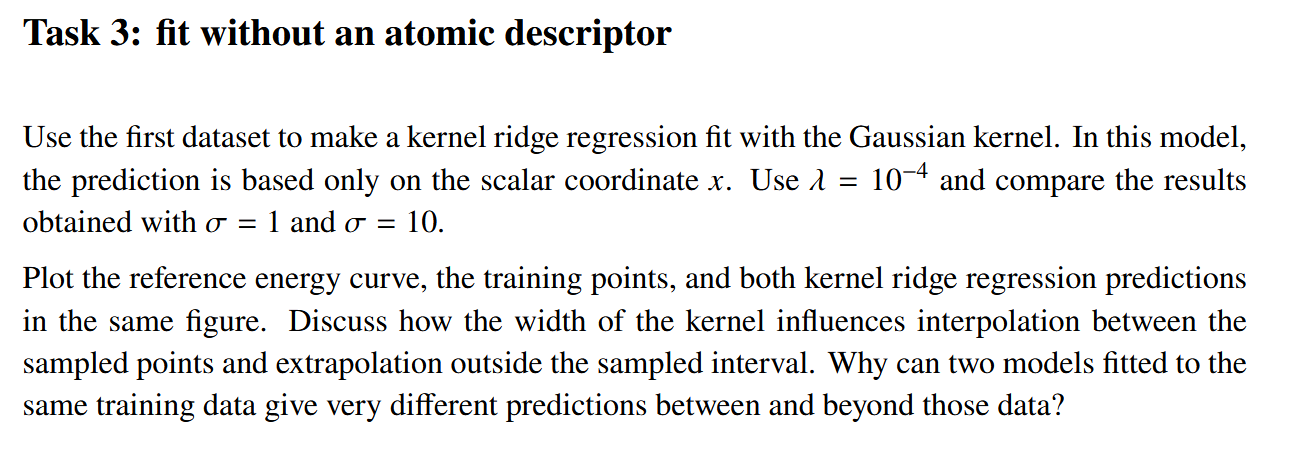

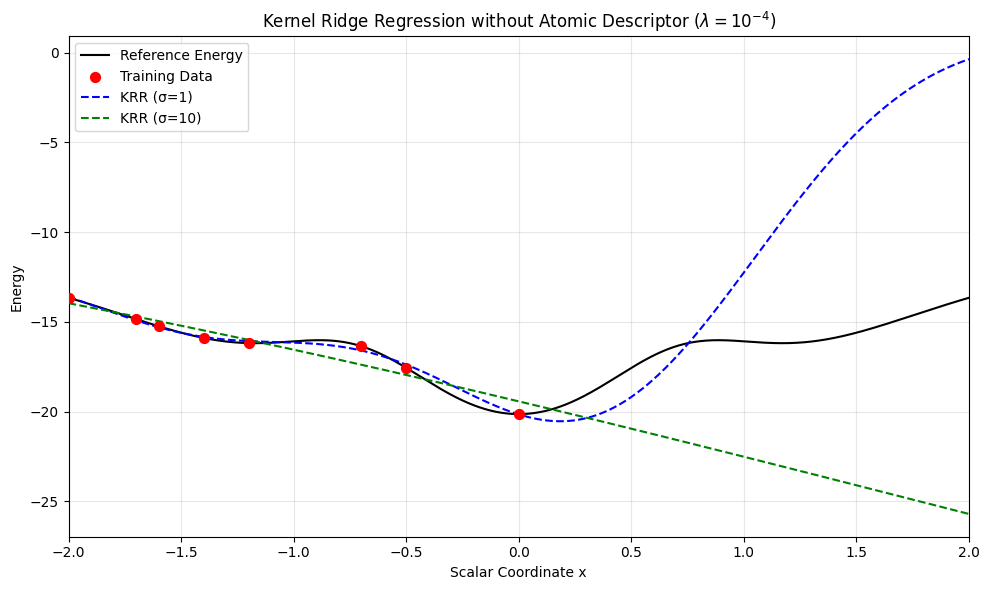

In [13]:
# Model 1: sigma = 1
krr_sig1 = KernalRidgeRegression(sigma=1.0, lam=1e-4)
krr_sig1.fit(xi, Ei)
y_pred_sig1 = krr_sig1.predict(xlin)

# Model 2: sigma = 10
krr_sig10 = KernalRidgeRegression(sigma=10.0, lam=1e-4)
krr_sig10.fit(xi, Ei)
y_pred_sig10 = krr_sig10.predict(xlin)

# Plot reference energy curve, training points, and both KRR predictions
fig, ax = plt.subplots(figsize=(10, 6))

ylin = potential(xlin)
ax.plot(xlin, ylin, color='black', label='Reference Energy')
ax.scatter(xi, Ei, color='red', s=50, zorder=5, label='Training Data')

ax.plot(xlin, y_pred_sig1, 'b--', label='KRR (σ=1)')
ax.plot(xlin, y_pred_sig10, 'g--', label='KRR (σ=10)')

ax.set_xlabel('Scalar Coordinate x')
ax.set_ylabel('Energy')
ax.set_title(r'Kernel Ridge Regression without Atomic Descriptor $(λ = 10^{-4})$')
ax.set_xlim(-2, 2)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

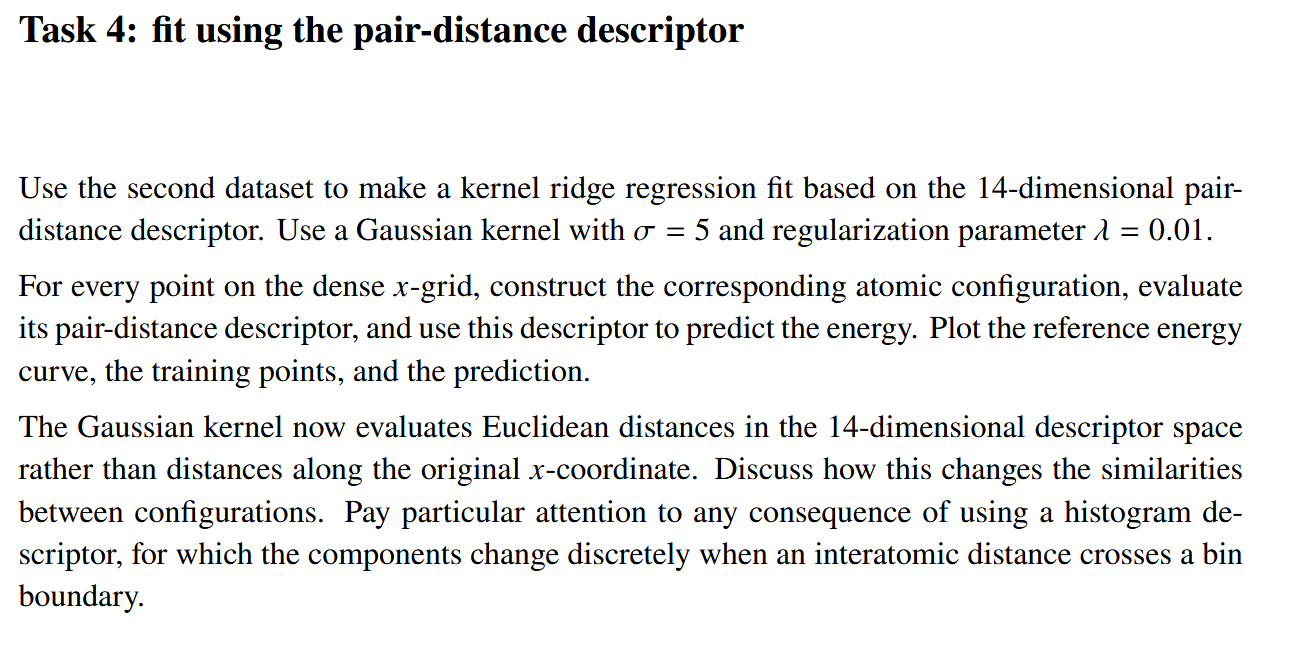

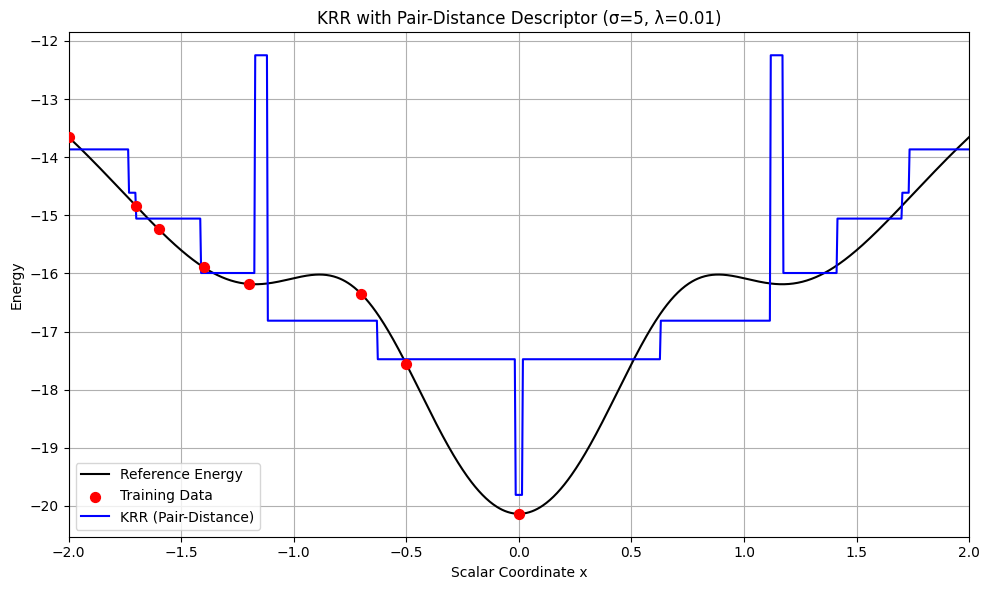

In [16]:
class VectorKernalRidgeRegression(KernalRidgeRegression):
    def K(self, x1, x2):
        # Override K to calculate the Euclidean distance for multidimensional vectors
        return np.exp(-np.sum((x1 - x2)**2) / (2 * self.sigma**2))

X2_lin = np.array([PairDistance(x) for x in xlin])

krr_pair = VectorKernalRidgeRegression(sigma=5.0, lam=0.01)
krr_pair.fit(X2, Ei)

y_pred_pair = krr_pair.predict(X2_lin)


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(xlin, ylin, color='black', label='Reference Energy')
ax.scatter(xi, Ei, color='red', s=50, zorder=5, label='Training Data')
ax.plot(xlin, y_pred_pair, color='blue', label='KRR (Pair-Distance)')

ax.set_xlabel('Scalar Coordinate x')
ax.set_ylabel('Energy')
ax.set_title(r'KRR with Pair-Distance Descriptor (σ=5, λ=0.01)')
ax.set_xlim(-2, 2)
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

### **Discussion Questions**

* **Changes in configuration similarities:** The Gaussian kernel now evaluates Euclidean distances in the 14-dimensional descriptor space rather than distances along the original x-coordinate. Because of this, similarity is no longer defined by how close the moving atom is along the x-axis, but by how closely the global distribution of interatomic distances matches between the two cluster configurations.


* **Consequences of a histogram descriptor:** Because the components change discretely when an interatomic distance crosses a bin boundary, the feature vectors undergo sudden, discontinuous jumps. As the moving atom shifts continuously across the x-axis, the resulting regression prediction forms a jagged, stepwise curve rather than a smooth physical potential.

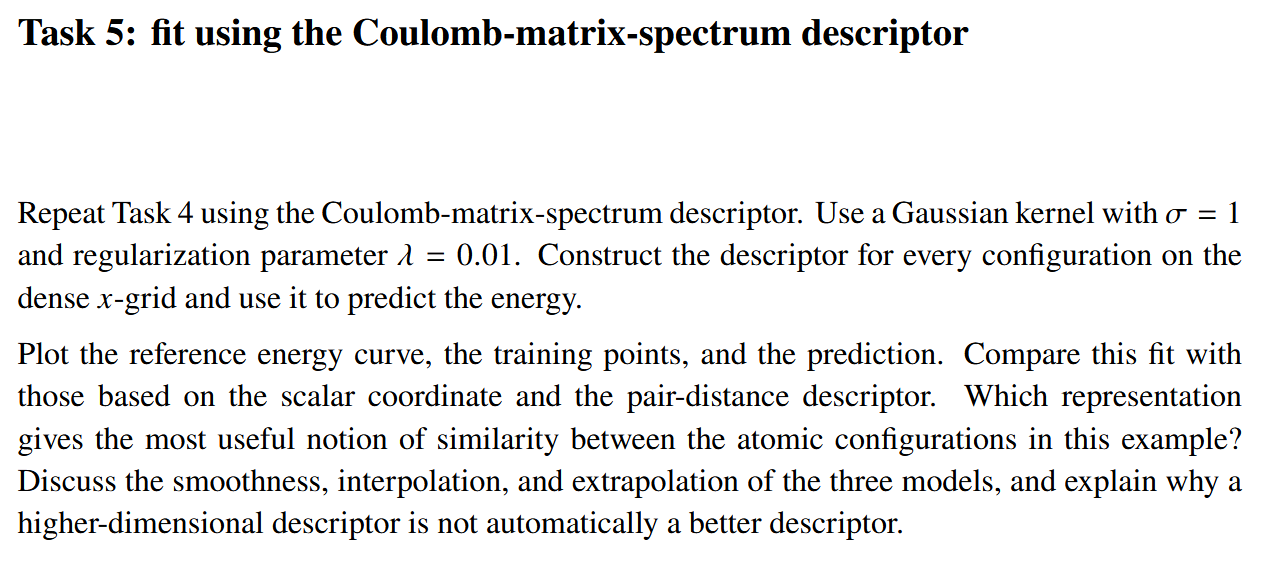

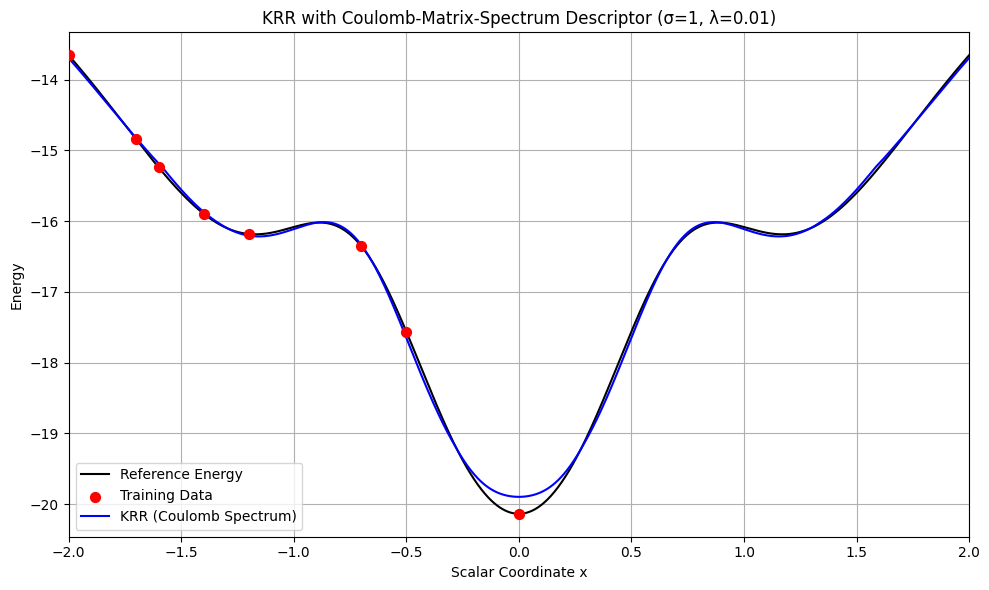

In [18]:
X3_lin = np.array([CoulombMatrixSpectrum(x) for x in xlin])

krr_coulomb = VectorKernalRidgeRegression(sigma=1.0, lam=0.01)
krr_coulomb.fit(X3, Ei)

y_pred_coulomb = krr_coulomb.predict(X3_lin)


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(xlin, ylin, color='black', label='Reference Energy')
ax.scatter(xi, Ei, color='red', s=50, zorder=5, label='Training Data')
ax.plot(xlin, y_pred_coulomb, color='blue', label='KRR (Coulomb Spectrum)')

ax.set_xlabel('Scalar Coordinate x')
ax.set_ylabel('Energy')
ax.set_title(r'KRR with Coulomb-Matrix-Spectrum Descriptor (σ=1, λ=0.01)')
ax.set_xlim(-2, 2)
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

### **Discussion Answers**

* **Comparison and Similarity:** The Coulomb-matrix-spectrum descriptor produces a continuous, smooth fit compared to the blocky pair-distance descriptor because matrix eigenvalues change smoothly as atomic coordinates shift. However, for this highly constrained 1D example, the direct scalar coordinate provides the most useful and direct notion of similarity, as the system's energy changes are driven entirely by movement along that single axis.


* **Smoothness, Interpolation, and Extrapolation:**
* The scalar coordinate model provides a smooth curve where interpolation behavior is easily tuned by $\sigma$, and extrapolation predictably decays based on scalar distance.


* The pair-distance model lacks smoothness entirely, failing at interpolation due to abrupt step-changes across histogram bins.


* The Coulomb-matrix model smoothly interpolates the physical energy landscape, though it may introduce subtle oscillations depending on how the non-linear eigenvalues map distances. Like all standard Gaussian kernel methods, it extrapolates by decaying toward zero as the configuration moves far from the training data.




* **Why higher-dimensional is not automatically better:** Increasing dimensionality can introduce unhelpful complexity, mathematical artifacts (such as rigid bin boundaries), or redundant information that distorts the kernel's distance calculation. If the extra dimensions do not smoothly and proportionally reflect the underlying physical properties, the kernel will measure similarity poorly, degrading the regression model's predictive power rather than enhancing it.